# Multiclass Classification

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

In [2]:
torch.__version__

'2.12.0+cu126'

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"

## 1. Get Data

In [4]:
N_SAMPLES = 1000
N_FEATURES = 2
N_CLUSTERS = 4
RANDOM_SEED = 42

X, y = make_blobs(n_samples=N_SAMPLES, n_features=N_FEATURES, centers=N_CLUSTERS, cluster_std=1.5, random_state=RANDOM_SEED)  # type: ignore[assignment]

X.shape, y.shape

((1000, 2), (1000,))

In [5]:
X = torch.from_numpy(X).type(torch.float32)
y = torch.from_numpy(y).type(torch.LongTensor)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED)
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

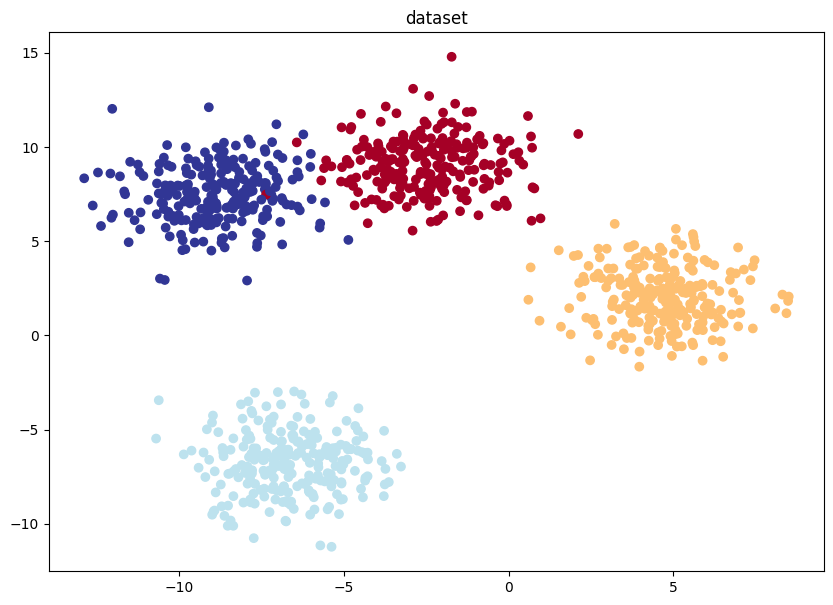

In [7]:
# visualize
plt.figure(figsize=(10, 7))
plt.title("dataset")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="RdYlBu")

## 2. Build Model

In [8]:
class MultiClassificationModel(nn.Module):
    def __init__(self, in_features, out_features, hidden_features):
        super().__init__()
        self.layers_stack = nn.Sequential(
            nn.Linear(in_features=in_features, out_features=hidden_features),
            nn.ReLU(),
            nn.Linear(in_features=hidden_features, out_features=hidden_features),
            nn.ReLU(),
            nn.Linear(in_features=hidden_features, out_features=out_features),
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers_stack(x)

multi_model = MultiClassificationModel(2, N_CLUSTERS, 8).to(device)
multi_model

MultiClassificationModel(
  (layers_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [9]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=multi_model.parameters(), lr=0.01)

## 3. How to get the result from a multi-class classification model?


`logits` -> `softmax()` -> `probabilities` -> `argmax()` -> `classifications`

In [10]:
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

multi_model.eval()
with torch.inference_mode():
    logits = multi_model(X_train[:10])
    probabilities = torch.softmax(logits, dim=1)
    predictions = torch.argmax(probabilities, dim=1)

print(f"logits:\n{logits}\n\nprobabilities:\n{probabilities}\n\npredictions:\n{predictions}")

logits:
tensor([[ 0.1351, -0.1182,  0.3529, -0.1315],
        [-0.0432, -0.2262,  0.2761, -0.0816],
        [ 0.3373, -0.5265,  0.3540, -0.2079],
        [ 0.0827, -0.3913,  0.2941, -0.1221],
        [-0.0432, -0.2262,  0.2761, -0.0816],
        [ 0.0151, -0.1804,  0.2834, -0.1097],
        [-0.0432, -0.2262,  0.2761, -0.0816],
        [ 0.0960, -0.1408,  0.3341, -0.1218],
        [ 0.1953, -0.6710,  0.4733, -0.4311],
        [-0.0432, -0.2262,  0.2761, -0.0816]], device='cuda:0')

probabilities:
tensor([[0.2642, 0.2051, 0.3284, 0.2023],
        [0.2397, 0.1997, 0.3299, 0.2307],
        [0.3313, 0.1397, 0.3369, 0.1921],
        [0.2723, 0.1695, 0.3364, 0.2219],
        [0.2397, 0.1997, 0.3299, 0.2307],
        [0.2492, 0.2049, 0.3259, 0.2200],
        [0.2397, 0.1997, 0.3299, 0.2307],
        [0.2589, 0.2043, 0.3285, 0.2082],
        [0.3053, 0.1284, 0.4031, 0.1632],
        [0.2397, 0.1997, 0.3299, 0.2307]], device='cuda:0')

predictions:
tensor([2, 2, 2, 2, 2, 2, 2, 2, 2, 2], device=

## 4. Train and Test

In [11]:
def accuracy_fn(y_true, y_pred):
    # TP / all
    tp = torch.eq(y_true, y_pred).sum().item()
    return (tp / len(y_pred)) * 100

In [12]:
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

epochs = 100

for epoch in range(epochs):
    multi_model.train()
    train_logits = multi_model(X_train)
    train_pred = torch.softmax(train_logits, dim=1).argmax(dim=1)
    train_loss = loss_fn(train_logits, y_train)
    train_acc = accuracy_fn(y_train, train_pred)
    
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    multi_model.eval()
    with torch.inference_mode():
        test_logits = multi_model(X_test)
        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_test, test_pred)
    
    if epoch % 10 == 0:
        print(f"epoch: {epoch} | loss: {train_loss:.5f} ; acc: {train_acc:.2f}% | test loss: {test_loss:.5f} ; test acc: {test_acc:.2f}%")

epoch: 0 | loss: 1.47527 ; acc: 17.75% | test loss: 1.42424 ; test acc: 26.50%
epoch: 10 | loss: 1.00636 ; acc: 75.75% | test loss: 1.00185 ; test acc: 66.00%
epoch: 20 | loss: 0.58770 ; acc: 89.25% | test loss: 0.60413 ; test acc: 88.00%
epoch: 30 | loss: 0.37950 ; acc: 96.12% | test loss: 0.41017 ; test acc: 95.50%
epoch: 40 | loss: 0.28665 ; acc: 97.75% | test loss: 0.31734 ; test acc: 97.50%
epoch: 50 | loss: 0.23660 ; acc: 98.25% | test loss: 0.26426 ; test acc: 99.00%
epoch: 60 | loss: 0.20253 ; acc: 99.00% | test loss: 0.22571 ; test acc: 99.50%
epoch: 70 | loss: 0.17597 ; acc: 99.00% | test loss: 0.19545 ; test acc: 99.50%
epoch: 80 | loss: 0.15325 ; acc: 99.12% | test loss: 0.16877 ; test acc: 99.50%
epoch: 90 | loss: 0.13071 ; acc: 99.12% | test loss: 0.14138 ; test acc: 99.50%


In [13]:
from helper_functions import plot_decision_boundary

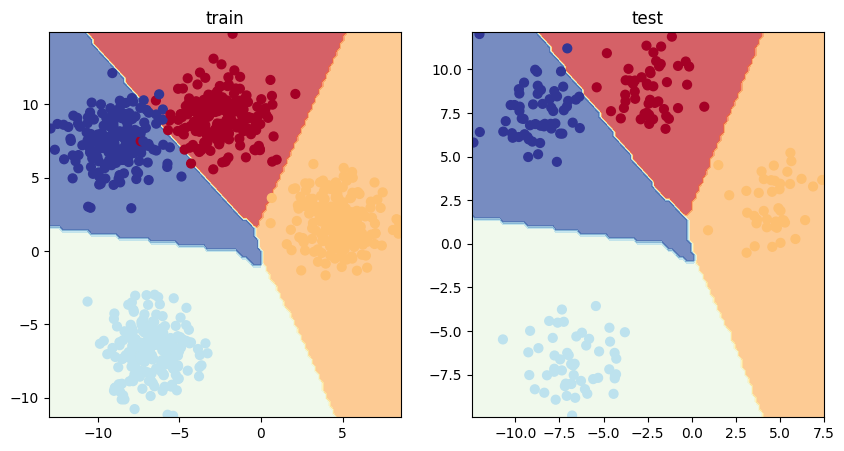

In [14]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("train")
plot_decision_boundary(multi_model, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("test")
plot_decision_boundary(multi_model, X_test, y_test)

## 5. Evaluate 评估
1. sklearn
2. torchmetrics

In [33]:
# plot_decision_boundary会放到cpu, 要手动放回cuda
multi_model = multi_model.to(device)

In [34]:
from torchmetrics.classification import MulticlassAccuracy
Acc = MulticlassAccuracy(N_CLUSTERS).to(device)
Acc

MulticlassAccuracy()

In [43]:
multi_model.eval()
with torch.inference_mode():
    test_logits = multi_model(X_test)
    test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
    test_loss = loss_fn(test_logits, y_test)
    test_acc = Acc(test_pred, y_test)
test_acc = Acc.compute()
print(f"Acc: {test_acc}")
Acc.reset()

Acc: 0.9956140518188477
